In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import LabelEncoder

In [2]:
def show_rgb_image(image, title=None, conversion=cv2.COLOR_BGR2RGB):

    # Converts from one colour space to the other. this is needed as RGB
    # is not the default colour space for OpenCV
    image = cv2.cvtColor(image, conversion)

    # Show the image
    plt.imshow(image)

    # remove the axis / ticks for a clean looking image
    plt.xticks([])
    plt.yticks([])

    # if a title is provided, show it
    if title is not None:
        plt.title(title)

    plt.show()

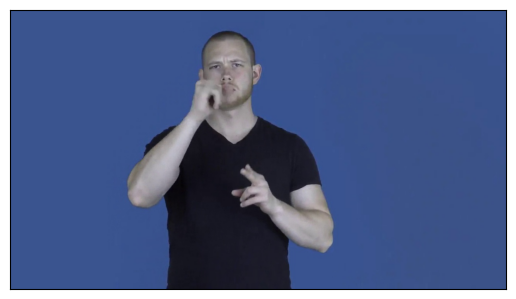

In [3]:
img_path = "../data/train/people/Deaf_vs_deaf_frame_009.jpg"

train_img = cv2.imread(img_path)

show_rgb_image(train_img)


In [4]:
sift = cv2.SIFT_create(nfeatures=1000)

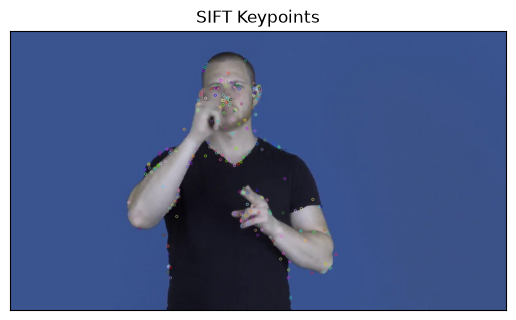

In [5]:
kp, des = sift.detectAndCompute(train_img, None)

img_with_keypoints = cv2.drawKeypoints(train_img, kp, None)

show_rgb_image(img_with_keypoints, title="SIFT Keypoints", conversion=cv2.COLOR_BGR2RGB)

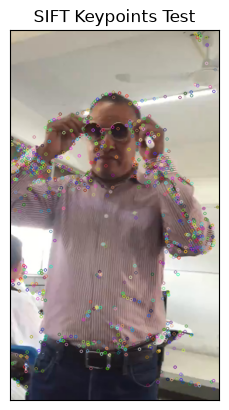

In [6]:
test_img_path = "../data/test/people/full-body.mp4_frame_000.jpg"

test_img = cv2.imread(test_img_path)

kp_test, des_test = sift.detectAndCompute(test_img, None)

img_with_keypoints_test = cv2.drawKeypoints(test_img, kp_test, None)

show_rgb_image(img_with_keypoints_test, title="SIFT Keypoints Test", conversion=cv2.COLOR_BGR2RGB)

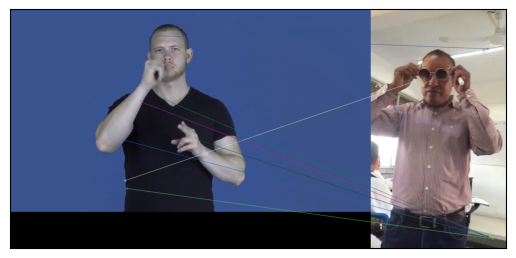

In [7]:
bf = cv2.BFMatcher(cv2.NORM_L2)
ratio_thresh = 0.75
matches = bf.knnMatch(des, des_test, k=2)

# Lowe's ratio test
good_matches = []
for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_thresh * n.distance:
            good_matches.append(m)

image_matching = cv2.drawMatches(train_img, kp, test_img, kp_test, good_matches, None, flags=2)
show_rgb_image(image_matching)

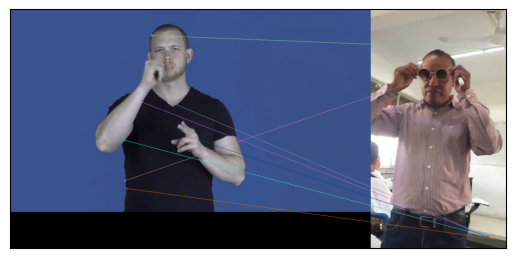

In [8]:
test_img_gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)
train_img_gray = cv2.cvtColor(train_img, cv2.COLOR_BGR2GRAY)

train_kp, train_des = sift.detectAndCompute(train_img_gray, None)
test_kp, test_des = sift.detectAndCompute(test_img_gray, None)

bf.knnMatch(train_des, test_des, k=2)

good_matches = []
for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_thresh * n.distance:
            good_matches.append(m)

image_matching_gray = cv2.drawMatches(train_img, kp, test_img, kp_test, good_matches, None, flags=2)
show_rgb_image(image_matching_gray)

In [9]:
def load_split(split_name, max_samples_per_class=None):
    """
    Load images and labels from a folder (train/test).
    Dynamically reads all subfolders (classes).
    """
    split_dir = Path("../data") / split_name
    if not split_dir.exists():
        split_dir = Path("data") / split_name
    if not split_dir.exists():
        raise FileNotFoundError(f"Split directory not found: {split_dir}")

    # Discover all object label subfolders
    classes = sorted([d.name for d in split_dir.iterdir() if d.is_dir()])
    
    images = []
    labels = []

    for cls_name in classes:
        cls_folder = split_dir / cls_name
        files = sorted(list(cls_folder.glob("*.jpg")) + list(cls_folder.glob("*.jpeg")))
        if max_samples_per_class:
            files = files[:max_samples_per_class]

        for file_path in files:
            img_item = cv2.imread(str(file_path))
            if img_item is not None:
                images.append(img_item)
                labels.append(cls_name)

    return np.array(images, dtype=object), np.array(labels), classes

X_train_images, y_train, classes = load_split("train")
X_test_images, y_test, _ = load_split("test")

print(f"Discovered Classes: {classes}")
print(f"Training samples:   {len(X_train_images)} images")
print(f"Test samples:       {len(X_test_images)} images")


Discovered Classes: ['apples', 'dogs', 'people']
Training samples:   523 images
Test samples:       140 images


In [10]:
train_kps = []
train_des = []
test_kps = []
test_des = []

for img_item in X_train_images:
    item_kp, item_des = sift.detectAndCompute(img_item, None)
    train_kps.append(item_kp)
    train_des.append(item_des)

for img_item in X_test_images:
    item_kp, item_des = sift.detectAndCompute(img_item, None)
    train_kps.append(item_kp)
    train_des.append(item_des)


In [11]:
def match_all_images(kp, desc, ratio_thresh=0.75):
    """Match two images using SIFT and Lowe's ratio test."""
    
    if kp is None or desc is None:
        return "No features detected"
    
    bf = cv2.BFMatcher(cv2.NORM_L2)

    best_match_index = None
    best_matches = []
    max_matches = 0

    for i in range(len(X_train_images)):
        if train_kps[i] is None or train_des[i] is None:
            continue

        matches = bf.knnMatch(desc, train_des[i], k=2)

        good_matches = []
        for pair in matches:
            if len(pair) == 2:
                m, n = pair
                if m.distance < ratio_thresh * n.distance:
                    good_matches.append(m)

        if best_match_index is None or len(good_matches) > max_matches:
            best_match_index = i
            best_matches = good_matches.copy()
            max_matches = len(good_matches)

    return best_match_index, best_matches

def detect_image(img):
    img_kp, img_des = sift.detectAndCompute(img, None)

    index, good_matches = match_all_images(img_kp, img_des)

    if index is None:
        print("No match found")
        return

    image_match = cv2.drawMatches(img, img_kp, X_train_images[index], train_kps[index], good_matches, None, flags=2)

    show_rgb_image(image_match)

    print(f"Best match with {y_train[index]} ({len(good_matches)})")

    





In [12]:
import random

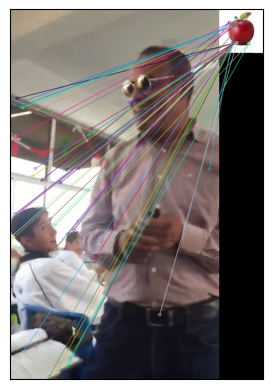

Best match with apples (49)


In [13]:
ran = random.randrange(len(X_test_images))
detect_image(X_test_images[ran])

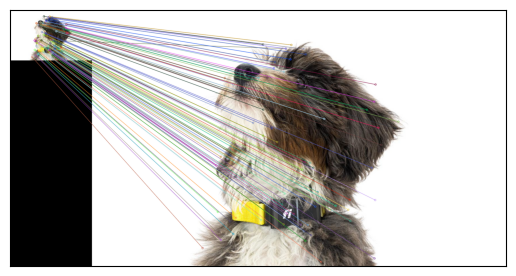

Best match with dogs (92)


In [14]:
ran = random.randrange(len(X_test_images))
detect_image(X_test_images[ran])

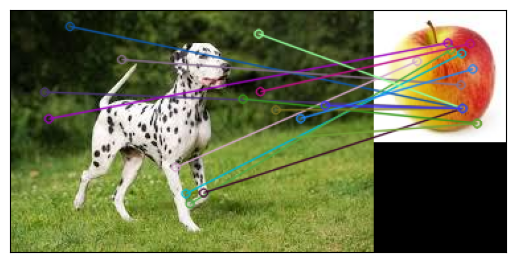

Best match with apples (15)


In [35]:
ran = random.randrange(len(X_test_images))
detect_image(X_test_images[ran])

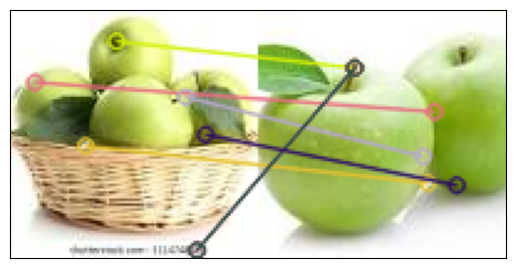

Best match with apples (7)


In [16]:
ran = random.randrange(len(X_test_images))
detect_image(X_test_images[ran])

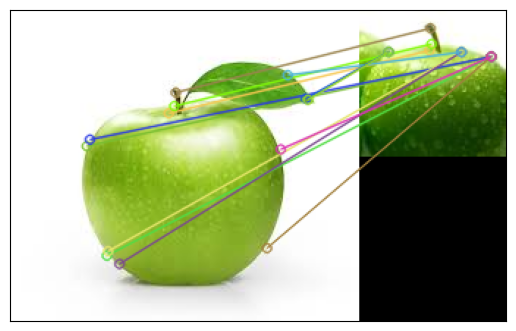

Best match with apples (13)


In [17]:
apple_img = cv2.imread("../data/test/apples/img_p2_41.jpeg")

detect_image(apple_img)

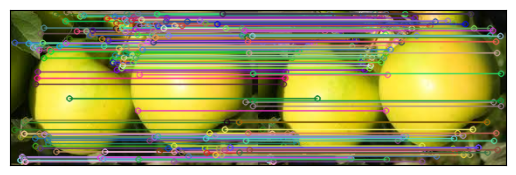

Best match with apples (171)


In [19]:
# Image from trainm should be a 1-to-1 match
apple_img_2 = cv2.imread("../data/train/apples/img_p3_117.jpeg")

detect_image(apple_img_2)